# 01 BÀN CỜ CỦA CỜ TƯ LỆNH

## Bàn cờ:
Bàn cờ chơi Cờ Tư Lệnh có hình chữ nhật, gồm 11 đường dọc và 12 đường ngang cắt nhau tạo thành 132 giao điểm.

## Các thành phần bàn cờ
Có một hàng trống ở giữa bàn cờ, được gọi là Sông (màu xanh đậm). Sông nằm ngang, chia bàn cờ thành hai phần đối xứng bằng nhau gọi là “Chiến tuyến”. Trên sông có hai đoạn nước nông, dưới có nền đá (có các gạch chấm), được gọi là Ngầm, mọi phương tiện được phép qua lại đoạn ngầm này. Phần còn lại của sông là nước sâu, phương tiện không được đi qua.

Bên trái bàn cờ của người chơi thứ nhất (bên phải bàn cờ của người chơi thứ hai) có hai dãy ô vuông chạy dọc suốt hai chiến tuyến, được quy ước là Biển (in màu xanh đậm).

## Tọa độ bàn cờ
Trục tung (dọc) của bàn cờ được đánh số từ 0 đến 11. Trục hoành (ngang) đánh số từ 0 đến 10. Gốc của trục tọa độ là góc dưới cùng bên trái bàn cờ khu bên vùng biển (đánh số từ 0).

Mỗi một giao điểm đều có tên tọa độ, tọa độ theo quy định đọc số trục tung trước, số trục hoành sau. Điểm gốc là (0, 0), điểm cao nhất là (11, 10).
Ví dụ: điểm (3, 5) đọc là ba năm; điểm (0, 0) đọc là không không; điểm (0, 7) không bảy; điểm (0, 10) không mười; điểm (11, 10); điểm (11, 0); điểm (8, 4).

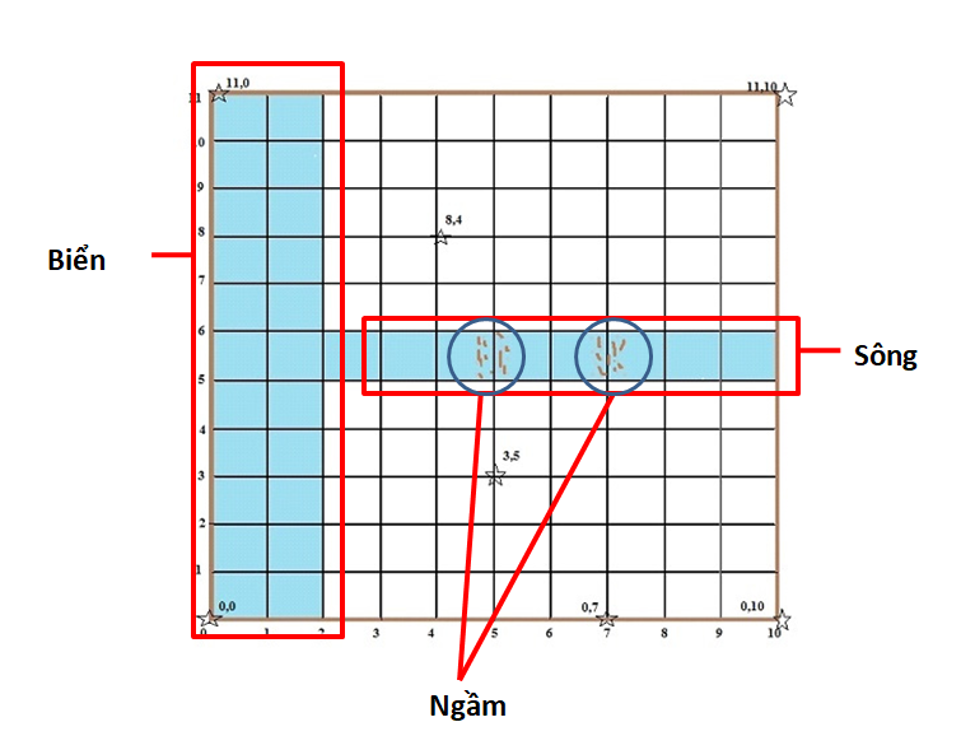

---

# Phần 1: Mục tiêu và phạm vi

### 1.1. Mục tiêu
Kiểm thử toàn diện biểu diễn bàn cờ, hệ tọa độ, các miền địa hình và phân loại đoạn nối trực giao giữa các giao điểm, đảm bảo tuân thủ tuyệt đối quy chuẩn luật Cờ Tư Lệnh.

### 1.2. Phạm vi kiểm thử
1. **Cấu trúc & Kích thước:** Bàn cờ chữ nhật 12 hàng ($y \in [0, 11]$) và 11 cột ($x \in [0, 10]$), tổng cộng 132 giao điểm.
2. **Hệ tọa độ $(y, x)$:** Xác thực tính hợp lệ của tọa độ trong và ngoài biên bàn cờ.
3. **Phân bố địa hình (Terrain):** 4 miền địa hình gồm Đất liền (`LAND`), Biển (`SEA`), Bờ sông (`RIVER_BANK`), Bờ biển (`COAST`).
4. **Phân loại đoạn nối (EdgeType):** 241 đoạn nối kề trực giao gồm Bình thường (`NORMAL`) bao gồm vùng biển và vùng đất liền, Dọc bờ sông (`RIVER_BANK`), Dọc bờ biển (`COAST`), Sông sâu (`DEEP_RIVER`), Ngầm đá vượt sông (`FORD`).
5. **Ngoại lệ & Xử lý biên:** Bắt lỗi chính xác khi tọa độ nằm ngoài bàn cờ hoặc 2 điểm không kề nhau.
6. **Trực quan hóa:** Hiển thị bản đồ SVG và sơ đồ phân loại địa hình.

### 1.3. Đầu ra: Tiêu chí nghiệm thu (Acceptance Criteria)
- Kiểm tra đúng kích thước + tọa độ.
- Phân loại đúng địa hình.
- Phân loại đúng đoạn nối.

# Phần 2: Import và cấu hình

In [7]:
from pathlib import Path
import sys
import random
from collections import Counter, defaultdict
import pandas as pd
from IPython.display import SVG, display, HTML
from html import escape

# 1. Cấu hình đường dẫn nạp module engine
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "packages").is_dir() and (p / "research").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Hãy mở notebook từ thư mục repo Commander-Chess-AI")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if str(PROJECT_ROOT / "packages") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "packages"))

# Thiết lập seed tái lập
random.seed(42)

# 2. Nạp module Board từ engine
from commander_game_engine.board import Board, Terrain, EdgeType

# 3. Khởi tạo Board
board = Board()

print("=" * 60)
print(f"KHỞI TẠO BOARD THÀNH CÔNG:")
print(f" - Số hàng (ROWS): {board.ROWS} (từ 0 đến 11)")
print(f" - Số cột  (COLS): {board.COLS} (từ 0 đến 10)")
print(f" - Tổng số giao điểm: {board.ROWS * board.COLS} điểm")
print("=" * 60)

assert (board.ROWS, board.COLS) == (12, 11), "Kích thước bàn cờ phải là 12x11"
assert board.ROWS * board.COLS == 132, "Tổng số giao điểm phải bằng 132"
print("PASS ĐÚNG KÍCH THƯỚC.")


KHỞI TẠO BOARD THÀNH CÔNG:
 - Số hàng (ROWS): 12 (từ 0 đến 11)
 - Số cột  (COLS): 11 (từ 0 đến 10)
 - Tổng số giao điểm: 132 điểm
PASS ĐÚNG KÍCH THƯỚC.


# Phần 3: Kiểm thử tọa độ


In [2]:
coord_test_cases = [
    # 4 góc biên bàn cờ
    ("TC-COORD-01", (0, 0), True, "Góc dưới cùng bên trái (gốc tọa độ - Biển)"),
    ("TC-COORD-02", (0, 10), True, "Góc dưới cùng bên phải (Đất liền Đỏ)"),
    ("TC-COORD-03", (11, 0), True, "Góc trên cùng bên trái (Biển Xanh)"),
    ("TC-COORD-04", (11, 10), True, "Góc trên cùng bên phải (Đất liền Xanh)"),
    # Điểm đặc thù trên sông, ngầm đá
    ("TC-COORD-05", (5, 5), True, "Ngầm đá 1 (Bờ sông Đỏ - giao điểm phía nam)"),
    ("TC-COORD-06", (6, 5), True, "Ngầm đá 1 (Bờ sông Xanh - giao điểm phía bắc)"),
    ("TC-COORD-07", (5, 7), True, "Ngầm đá 2 (Bờ sông Đỏ)"),
    ("TC-COORD-08", (6, 7), True, "Ngầm đá 2 (Bờ sông Xanh)"),
    ("TC-COORD-09", (5, 2), True, "Giao điểm ngã ba bờ biển - bờ sông"),
    # Tọa độ ngoài biên
    ("TC-COORD-10", (-1, 0), False, "Ngoài biên y âm (dưới hàng 0)"),
    ("TC-COORD-11", (0, -1), False, "Ngoài biên x âm (trái cột 0)"),
    ("TC-COORD-12", (12, 0), False, "Ngoài biên y vượt quá ROWS (trên hàng 11)"),
    ("TC-COORD-13", (0, 11), False, "Ngoài biên x vượt quá COLS (phải cột 10)"),
    ("TC-COORD-14", (-1, -1), False, "Góc âm ngoài biên (-1, -1)"),
    ("TC-COORD-15", (12, 11), False, "Góc dương ngoài biên (12, 11)"),
]

coord_records = []
for tc_id, pos, expected, desc in coord_test_cases:
    actual = board.is_valid_position(pos)
    passed = (actual == expected)
    coord_records.append({
        "Mã Test": tc_id,
        "Tọa độ": str(pos),
        "Mô tả": desc,
        "Kỳ vọng": "Hợp lệ" if expected else "Không hợp lệ",
        "Thực tế": "Hợp lệ" if actual else "Không hợp lệ",
        "Kết quả": "PASS" if passed else "FAIL"
    })

# Quét kiểm tra toàn bộ 132 giao điểm
all_132_valid = all(board.is_valid_position((y, x)) for y in range(board.ROWS) for x in range(board.COLS))
coord_records.append({
    "Mã Test": "TC-COORD-16",
    "Tọa độ": "Tất cả 132 điểm",
    "Mô tả": "Duyệt toàn bộ lưới [0..11] x [0..10]",
    "Kỳ vọng": "132/132 Hợp lệ",
    "Thực tế": "132/132 Hợp lệ" if all_132_valid else "Có điểm lỗi",
    "Kết quả": "PASS" if all_132_valid else "FAIL"
})

df_coord = pd.DataFrame(coord_records)
print("=== BẢNG PASS/FAIL: KIỂM THỬ TỌA ĐỘ BÀN CỜ ===")
display(df_coord)

# Xác nhận nghiệm thu
pass_count = sum(1 for r in coord_records if r["Kết quả"] == "PASS")
fail_count = len(coord_records) - pass_count
print(f"\nTổng số ca test: {len(coord_records)} | PASS: {pass_count} | FAIL: {fail_count}")
assert fail_count == 0, f"Có {fail_count} ca kiểm thử tọa độ thất bại!"
print("PASS ĐÚNG TỌA ĐỘ.")


=== BẢNG PASS/FAIL: KIỂM THỬ TỌA ĐỘ BÀN CỜ ===


,Mã Test,Tọa độ,Mô tả,Kỳ vọng,Thực tế,Kết quả
0,TC-COORD-01,"(0, 0)",Góc dưới cùng bên trái (gốc tọa độ - Biển),Hợp lệ,Hợp lệ,PASS
1,TC-COORD-02,"(0, 10)",Góc dưới cùng bên phải (Đất liền Đỏ),Hợp lệ,Hợp lệ,PASS
2,TC-COORD-03,"(11, 0)",Góc trên cùng bên trái (Biển Xanh),Hợp lệ,Hợp lệ,PASS
3,TC-COORD-04,"(11, 10)",Góc trên cùng bên phải (Đất liền Xanh),Hợp lệ,Hợp lệ,PASS
4,TC-COORD-05,"(5, 5)",Ngầm đá 1 (Bờ sông Đỏ - giao điểm phía nam),Hợp lệ,Hợp lệ,PASS
5,TC-COORD-06,"(6, 5)",Ngầm đá 1 (Bờ sông Xanh - giao điểm phía bắc),Hợp lệ,Hợp lệ,PASS
6,TC-COORD-07,"(5, 7)",Ngầm đá 2 (Bờ sông Đỏ),Hợp lệ,Hợp lệ,PASS
7,TC-COORD-08,"(6, 7)",Ngầm đá 2 (Bờ sông Xanh),Hợp lệ,Hợp lệ,PASS
8,TC-COORD-09,"(5, 2)",Giao điểm ngã ba bờ biển - bờ sông,Hợp lệ,Hợp lệ,PASS
9,TC-COORD-10,"(-1, 0)",Ngoài biên y âm (dưới hàng 0),Không hợp lệ,Không hợp lệ,PASS



Tổng số ca test: 16 | PASS: 16 | FAIL: 0
PASS ĐÚNG TỌA ĐỘ.


# Phần 4: Kiểm thử địa hình

In [3]:
terrain_counts = Counter()
terrain_samples = defaultdict(list)
terrain_errors = []

for y in range(board.ROWS):
    for x in range(board.COLS):
        try:
            t = board.get_region(y, x)
            terrain_counts[t] += 1
            if len(terrain_samples[t]) < 4:
                terrain_samples[t].append((y, x))
        except Exception as e:
            terrain_errors.append(((y, x), str(e)))

expected_terrains = {
    Terrain.LAND: (80, "Đất liền (Land)"),
    Terrain.SEA: (24, "Vùng biển (Sea)"),
    Terrain.RIVER_BANK: (18, "Bờ sông (River Bank)"),
    Terrain.COAST: (10, "Bờ biển (Coast)"),
}

terrain_summary = []
for t, (exp_count, name_vn) in expected_terrains.items():
    act_count = terrain_counts[t]
    status = "PASS" if act_count == exp_count else "FAIL"
    pct = (act_count / (board.ROWS * board.COLS)) * 100
    samples_str = ", ".join(str(p) for p in terrain_samples[t])
    terrain_summary.append({
        "Địa hình (Enum)": t.value,
        "Tên địa hình": name_vn,
        "Số lượng thực tế": act_count,
        "Kỳ vọng": exp_count,
        "Tỷ lệ (%)": f"{pct:.1f}%",
        "Tọa độ mẫu": samples_str,
        "Kết quả": status
    })

df_terrain = pd.DataFrame(terrain_summary)
print("=== BẢNG PHÂN BỐ ĐỊA HÌNH (TERRAIN) TRÊN BÀN CỜ ===")
display(df_terrain)

# Kiểm tra tính toàn vẹn
assert len(terrain_errors) == 0, f"Có lỗi xảy ra tại các tọa độ: {terrain_errors}"
assert sum(terrain_counts.values()) == 132, "Tổng số giao điểm địa hình phải đúng bằng 132"
for t, (exp_count, _) in expected_terrains.items():
    assert terrain_counts[t] == exp_count, f"Địa hình {t.value} có {terrain_counts[t]} điểm, kỳ vọng {exp_count}"

print(f"\nTổng số giao điểm đã phân loại: {sum(terrain_counts.values())}/132 | Số lỗi: {len(terrain_errors)}")
print("PASS PHÂN LOẠI ĐÚNG VỊ TRÍ ĐỊA HÌNH.")


=== BẢNG PHÂN BỐ ĐỊA HÌNH (TERRAIN) TRÊN BÀN CỜ ===


,Địa hình (Enum),Tên địa hình,Số lượng thực tế,Kỳ vọng,Tỷ lệ (%),Tọa độ mẫu,Kết quả
0,land,Đất liền (Land),80,80,60.6%,"(0, 3), (0, 4), (0, 5), (0, 6)",PASS
1,sea,Vùng biển (Sea),24,24,18.2%,"(0, 0), (0, 1), (1, 0), (1, 1)",PASS
2,river_bank,Bờ sông (River Bank),18,18,13.6%,"(5, 2), (5, 3), (5, 4), (5, 5)",PASS
3,coast,Bờ biển (Coast),10,10,7.6%,"(0, 2), (1, 2), (2, 2), (3, 2)",PASS



Tổng số giao điểm đã phân loại: 132/132 | Số lỗi: 0
PASS PHÂN LOẠI ĐÚNG VỊ TRÍ ĐỊA HÌNH.


# Phần 5: Kiểm thử đoạn nối


In [4]:
edge_counts = Counter()
edge_samples = defaultdict(list)
edge_errors = []

for y in range(board.ROWS):
    for x in range(board.COLS):
        start = (y, x)
        for dy, dx in [(0, 1), (1, 0)]:
            end = (y + dy, x + dx)
            if board.is_valid_position(end):
                try:
                    etype = board.get_edge_type(start, end)
                    edge_counts[etype] += 1
                    # Kiểm tra tính đối xứng của đoạn nối
                    reverse_etype = board.get_edge_type(end, start)
                    assert etype == reverse_etype, f"Không đối xứng tại {start} <-> {end}"
                    edge_samples[etype].append((start, end))
                except Exception as e:
                    edge_errors.append((start, end, str(e)))

expected_edges = {
    EdgeType.NORMAL: (206, "Bình thường (Đất liền / Biển)"),
    EdgeType.RIVER_BANK: (16, "Dọc bờ sông (y=5, y=6; x>=2)"),
    EdgeType.COAST: (10, "Dọc bờ biển (x=2; trừ đoạn vượt sông)"),
    EdgeType.DEEP_RIVER: (7, "Sông sâu không qua lại ({y1,y2}={5,6}; x!=5,7)"),
    EdgeType.FORD: (2, "Ngầm đá vượt sông (x=5 và x=7)"),
}

edge_summary = []
for etype, (exp_count, desc) in expected_edges.items():
    act_count = edge_counts[etype]
    status = "PASS" if act_count == exp_count else "FAIL"
    pct = (act_count / 241) * 100
    edge_summary.append({
        "Loại đoạn nối (EdgeType)": etype.value,
        "Mô tả đặc điểm": desc,
        "Số lượng thực tế": act_count,
        "Kỳ vọng": exp_count,
        "Tỷ lệ (%)": f"{pct:.1f}%",
        "Kết quả": status
    })

df_edge = pd.DataFrame(edge_summary)
print("=== BẢNG PHÂN BỐ ĐOẠN NỐI (EDGETYPE) TRÊN BÀN CỜ ===")
display(df_edge)

# Kiểm tra chi tiết 2 ngầm đá
expected_fords = {((5, 5), (6, 5)), ((5, 7), (6, 7))}
actual_fords = set(edge_samples[EdgeType.FORD])
assert actual_fords == expected_fords, f"FORD không đúng vị trí: {actual_fords}"

# Bảng các đoạn sông sâu
df_deep_river = pd.DataFrame([
    {"Đoạn nối": f"{s} <-> {e}", "Loại": "DEEP_RIVER", "Tính chất": "Nước sâu, cấm phương tiện bộ binh/cơ giới qua"}
    for s, e in edge_samples[EdgeType.DEEP_RIVER]
])
print("\n--- Chi tiết 7 đoạn Sông Sâu (DEEP_RIVER) ---")
display(df_deep_river)

print(f"\nTổng số đoạn nối kiểm tra: {sum(edge_counts.values())}/241 | Số lỗi: {len(edge_errors)}")
print("PASS PHÂN LOẠI ĐÚNG VỊ TRÍ ĐOẠN NỐI.")


=== BẢNG PHÂN BỐ ĐOẠN NỐI (EDGETYPE) TRÊN BÀN CỜ ===


,Loại đoạn nối (EdgeType),Mô tả đặc điểm,Số lượng thực tế,Kỳ vọng,Tỷ lệ (%),Kết quả
0,normal,Bình thường (Đất liền / Biển),206,206,85.5%,PASS
1,river_bank,"Dọc bờ sông (y=5, y=6; x>=2)",16,16,6.6%,PASS
2,coast,Dọc bờ biển (x=2; trừ đoạn vượt sông),10,10,4.1%,PASS
3,deep_river,"Sông sâu không qua lại ({y1,y2}={5,6}; x!=5,7)",7,7,2.9%,PASS
4,ford,Ngầm đá vượt sông (x=5 và x=7),2,2,0.8%,PASS



--- Chi tiết 7 đoạn Sông Sâu (DEEP_RIVER) ---


,Đoạn nối,Loại,Tính chất
0,"(5, 2) <-> (6, 2)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"
1,"(5, 3) <-> (6, 3)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"
2,"(5, 4) <-> (6, 4)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"
3,"(5, 6) <-> (6, 6)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"
4,"(5, 8) <-> (6, 8)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"
5,"(5, 9) <-> (6, 9)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"
6,"(5, 10) <-> (6, 10)",DEEP_RIVER,"Nước sâu, cấm phương tiện bộ binh/cơ giới qua"



Tổng số đoạn nối kiểm tra: 241/241 | Số lỗi: 0
PASS PHÂN LOẠI ĐÚNG VỊ TRÍ ĐOẠN NỐI.


# Phần 6: Kiểm thử ngoại lệ, biên


In [5]:
exception_tests = [
    # 1. get_region ngoài biên
    ("TC-EXC-01", "board.get_region(-1, 0)", lambda: board.get_region(-1, 0), ValueError, "Invalid region coordinate"),
    ("TC-EXC-02", "board.get_region(12, 5)", lambda: board.get_region(12, 5), ValueError, "Invalid region coordinate"),
    ("TC-EXC-03", "board.get_region(0, 11)", lambda: board.get_region(0, 11), ValueError, "Invalid region coordinate"),
    # 2. get_edge_type tọa độ ngoài biên
    ("TC-EXC-04", "board.get_edge_type((-1, 0), (0, 0))", lambda: board.get_edge_type((-1, 0), (0, 0)), ValueError, "Invalid position"),
    ("TC-EXC-05", "board.get_edge_type((0, 0), (0, 11))", lambda: board.get_edge_type((0, 0), (0, 11)), ValueError, "Invalid position"),
    # 3. get_edge_type hai điểm không kề nhau
    ("TC-EXC-06", "board.get_edge_type((5, 5), (5, 5)) [trùng điểm]", lambda: board.get_edge_type((5, 5), (5, 5)), ValueError, "Points must be adjacent"),
    ("TC-EXC-07", "board.get_edge_type((0, 0), (1, 1)) [chéo]", lambda: board.get_edge_type((0, 0), (1, 1)), ValueError, "Points must be adjacent"),
    ("TC-EXC-08", "board.get_edge_type((0, 0), (0, 2)) [cách 2 ô]", lambda: board.get_edge_type((0, 0), (0, 2)), ValueError, "Points must be adjacent"),
    ("TC-EXC-09", "board.get_edge_type((0, 0), (3, 3)) [xa nhau]", lambda: board.get_edge_type((0, 0), (3, 3)), ValueError, "Points must be adjacent"),
]

exc_results = []
for tc_id, call_str, fn, exp_exc, exp_msg in exception_tests:
    try:
        fn()
        passed = False
        act_res = "Lỗi: Không ném ngoại lệ"
    except exp_exc as e:
        passed = (str(e) == exp_msg)
        act_res = f"{type(e).__name__}('{e}')"
    except Exception as e:
        passed = False
        act_res = f"Sai loại ngoại lệ: {type(e).__name__}('{e}')"
    
    exc_results.append({
        "Mã Test": tc_id,
        "Thao tác kiểm thử": call_str,
        "Ngoại lệ kỳ vọng": f"{exp_exc.__name__}('{exp_msg}')",
        "Kết quả thực tế": act_res,
        "Đánh giá": "PASS" if passed else "FAIL"
    })

df_exc = pd.DataFrame(exc_results)
print("=== BẢNG PASS/FAIL: KIỂM THỬ NGOẠI LỆ VÀ BIÊN DỮ LIỆU ===")
display(df_exc)

pass_exc = sum(1 for r in exc_results if r["Đánh giá"] == "PASS")
fail_exc = len(exc_results) - pass_exc
print(f"\nTổng số ca test ngoại lệ: {len(exc_results)} | PASS: {pass_exc} | FAIL: {fail_exc}")
assert fail_exc == 0, f"Có {fail_exc} ca test ngoại lệ không đạt!"
print("PASS Toàn bộ ngoại lệ được bắt và xử lý chuẩn xácxác.")


=== BẢNG PASS/FAIL: KIỂM THỬ NGOẠI LỆ VÀ BIÊN DỮ LIỆU ===


,Mã Test,Thao tác kiểm thử,Ngoại lệ kỳ vọng,Kết quả thực tế,Đánh giá
0,TC-EXC-01,"board.get_region(-1, 0)",ValueError('Invalid region coordinate'),ValueError('Invalid region coordinate'),PASS
1,TC-EXC-02,"board.get_region(12, 5)",ValueError('Invalid region coordinate'),ValueError('Invalid region coordinate'),PASS
2,TC-EXC-03,"board.get_region(0, 11)",ValueError('Invalid region coordinate'),ValueError('Invalid region coordinate'),PASS
3,TC-EXC-04,"board.get_edge_type((-1, 0), (0, 0))",ValueError('Invalid position'),ValueError('Invalid position'),PASS
4,TC-EXC-05,"board.get_edge_type((0, 0), (0, 11))",ValueError('Invalid position'),ValueError('Invalid position'),PASS
5,TC-EXC-06,"board.get_edge_type((5, 5), (5, 5)) [trùng điểm]",ValueError('Points must be adjacent'),ValueError('Points must be adjacent'),PASS
6,TC-EXC-07,"board.get_edge_type((0, 0), (1, 1)) [chéo]",ValueError('Points must be adjacent'),ValueError('Points must be adjacent'),PASS
7,TC-EXC-08,"board.get_edge_type((0, 0), (0, 2)) [cách 2 ô]",ValueError('Points must be adjacent'),ValueError('Points must be adjacent'),PASS
8,TC-EXC-09,"board.get_edge_type((0, 0), (3, 3)) [xa nhau]",ValueError('Points must be adjacent'),ValueError('Points must be adjacent'),PASS



Tổng số ca test ngoại lệ: 9 | PASS: 9 | FAIL: 0
PASS Toàn bộ ngoại lệ được bắt và xử lý chuẩn xácxác.


# Phần 7: Trực quan hóa
Trực quan hóa bàn cờ Cờ Tư Lệnh qua 2 phương thức:
  1. **Hình ảnh bàn cờ đồ họa chính thức:** Render file vector SVG từ tài nguyên dự án (`apps/web/public/assets/board/board.svg`).
  2. **Ma trận bàn cờ phân loại địa hình:** Hiển thị trực quan lưới $12 \times 11$ (132 giao điểm) với màu sắc và ký hiệu tương ứng cho từng miền địa hình (Biển, Bờ biển, Bờ sông, Đất liền, Ngầm đá).

Hiển thị bàn cờ SVG chính thức từ: apps\web\public\assets\board\board.svg


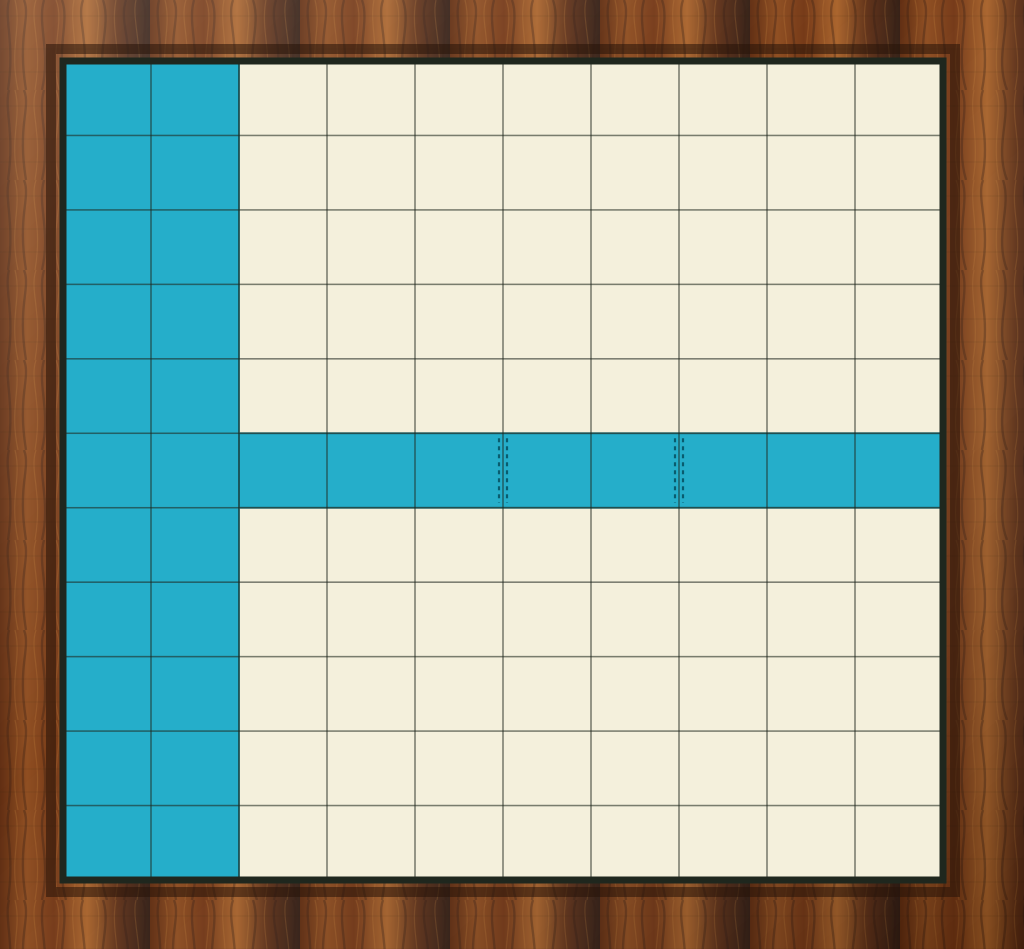

In [8]:
# 1. Trực quan hóa qua file SVG chính thức của bàn cờ
svg_path = PROJECT_ROOT / "apps/web/public/assets/board/board.svg"
if svg_path.exists():
    print(f"Hiển thị bàn cờ SVG chính thức từ: {svg_path.relative_to(PROJECT_ROOT)}")
    display(SVG(filename=str(svg_path)))
else:
    print(f"Không tìm thấy file SVG tại {svg_path}")

# 2. Xây dựng bảng ma trận phân loại địa hình bằng HTML màu sắc
COLORS = {
    Terrain.LAND: "#E8D6AD",
    Terrain.SEA: "#B6DCEB",
    Terrain.COAST: "#E6AD66",
    Terrain.RIVER_BANK: "#80B779",
}

# Kích thước SVG
CELL = 42
LEFT = 45
TOP = 40
WIDTH = LEFT + (board.COLS - 1) * CELL + 55
HEIGHT = TOP + (board.ROWS - 1) * CELL + 55

html = []

html.append("""
<div style="
    font-family: Arial, sans-serif;
    max-width: 750px;
    padding: 20px;
    border: 1px solid #ddd;
    border-radius: 10px;
    background: #fff;
    color: #222;
">
    <h3 style="margin-top:0">Board Geometry Visualization</h3>
    <p style="font-size:13px;color:#666">
        Commander Chess AI — Terrain and Edge Classification
    </p>
""")

html.append(
    f'<svg viewBox="0 0 {WIDTH} {HEIGHT}" '
    'style="width:100%;max-width:600px;height:auto">'
)

# 1. Vẽ nền địa hình tại các giao điểm
for y in range(board.ROWS):
    for x in range(board.COLS):
        terrain = board.get_region(y, x)
        color = COLORS[terrain]

        px = LEFT + x * CELL
        py = TOP + y * CELL

        html.append(
            f'<rect x="{px-CELL/2}" y="{py-CELL/2}" '
            f'width="{CELL}" height="{CELL}" '
            f'fill="{color}" opacity="0.85"/>'
        )

# 2. Vẽ các cạnh ngang và dọc theo EdgeType
edge_counts = Counter()

for y in range(board.ROWS):
    for x in range(board.COLS):
        start = (y, x)

        for dy, dx in [(0, 1), (1, 0)]:
            end = (y + dy, x + dx)

            if not board.is_valid_position(end):
                continue

            edge_type = board.get_edge_type(start, end)
            edge_counts[edge_type] += 1

            x1 = LEFT + x * CELL
            y1 = TOP + y * CELL
            x2 = LEFT + end[1] * CELL
            y2 = TOP + end[0] * CELL

            edge_color = "#655744"
            stroke_width = 1.2

            if edge_type == EdgeType.FORD:
                edge_color = "#16803C"
                stroke_width = 5

            elif edge_type == EdgeType.DEEP_RIVER:
                edge_color = "#D62828"
                stroke_width = 5

            html.append(
                f'<line x1="{x1}" y1="{y1}" '
                f'x2="{x2}" y2="{y2}" '
                f'stroke="{edge_color}" '
                f'stroke-width="{stroke_width}" '
                f'stroke-linecap="round"/>'
            )

# 3. Vẽ giao điểm
for y in range(board.ROWS):
    for x in range(board.COLS):
        px = LEFT + x * CELL
        py = TOP + y * CELL

        terrain = board.get_region(y, x)

        html.append(
            f'<circle cx="{px}" cy="{py}" r="3" fill="#3D332A">'
            f'<title>({y}, {x}) — {escape(terrain.value)}</title>'
            f'</circle>'
        )

# 4. Nhãn tọa độ
for x in range(board.COLS):
    px = LEFT + x * CELL
    html.append(
        f'<text x="{px}" y="{TOP-27}" '
        f'text-anchor="middle" font-size="12" fill="#333">{x}</text>'
    )

for y in range(board.ROWS):
    py = TOP + y * CELL
    html.append(
        f'<text x="{LEFT-30}" y="{py+4}" '
        f'text-anchor="middle" font-size="12" fill="#333">{y}</text>'
    )

html.append("</svg>")

# 5. Chú giải
html.append("""
<div style="
    display:flex;
    gap:15px;
    flex-wrap:wrap;
    font-size:12px;
    margin-top:15px;
">
    <span>🟫 LAND</span>
    <span>🟦 SEA</span>
    <span>🟧 COAST</span>
    <span>🟩 RIVER_BANK</span>
    <span style="color:#16803C;font-weight:bold">━━ FORD</span>
    <span style="color:#D62828;font-weight:bold">━━ DEEP_RIVER</span>
</div>
""")

# 6. Thống kê
terrain_counts = Counter(
    board.get_region(y, x)
    for y in range(board.ROWS)
    for x in range(board.COLS)
)

html.append(f"""
<div style="
    margin-top:18px;
    padding:12px;
    background:#f7f7f7;
    border-radius:6px;
    font-size:13px;
">
    <b>Geometry Summary</b>
    <p>Board: {board.ROWS} × {board.COLS} =
       {board.ROWS * board.COLS} intersections</p>
    <p>Total edges: {sum(edge_counts.values())}</p>
    <p>LAND: {terrain_counts[Terrain.LAND]} |
       SEA: {terrain_counts[Terrain.SEA]} |
       COAST: {terrain_counts[Terrain.COAST]} |
       RIVER_BANK: {terrain_counts[Terrain.RIVER_BANK]}</p>
    <p>FORD: {edge_counts[EdgeType.FORD]} |
       DEEP_RIVER: {edge_counts[EdgeType.DEEP_RIVER]}</p>
</div>
</div>
""")

display(HTML("".join(html)))

# END